In [27]:
import numpy as np
import re
from pathlib import Path
import pandas as pd
from scipy.signal import find_peaks

import matplotlib.pyplot as plt

In [28]:
# Caminho para a pasta de dados
diretorio_dados = Path("dados")

# Dicionário final: chave = (h, A, B), valor = Dicionário com {nome_coluna: np.array}
dados_dict = {}

# Expressão regular para extrair h, A e B do nome do ficheiro
padrao = re.compile(
    r"h([+-]?\d+(?:\.\d+)?)[_A-Za-z]*A([+-]?\d+(?:\.\d+)?)[_A-Za-z]*B([+-]?\d+(?:\.\d+)?)", 
    re.IGNORECASE
)

# Percorrer todos os ficheiros CSV na pasta
for ficheiro in diretorio_dados.glob("*.csv"):
    match = padrao.search(ficheiro.name)
    
    if match:
        # Extrair os valores e convertê-los para float
        h = float(match.group(1))
        a = float(match.group(2))
        b = float(match.group(3))
        
        # O triplo ordenado (tuplo) como chave principal
        chave = (h, a, b)
        
        # Ler o CSV com o pandas
        df = pd.read_csv(ficheiro)
        
        # Converter cada coluna do DataFrame num dicionário de NumPy arrays
        colunas_dict = {coluna: df[coluna].to_numpy() for coluna in df.columns}
        
        # Guardar no dicionário principal
        dados_dict[chave] = colunas_dict
        print(f"Processado: {ficheiro.name} -> Chave: {chave} ({len(df.columns)} colunas convertidas)")

print(f"\nTotal de ficheiros carregados com sucesso: {len(dados_dict)}")

Processado: h5_A3_B20.csv -> Chave: (5.0, 3.0, 20.0) (18 colunas convertidas)
Processado: h5_A0.5_B5.csv -> Chave: (5.0, 0.5, 5.0) (18 colunas convertidas)
Processado: h5_A3_B5.csv -> Chave: (5.0, 3.0, 5.0) (18 colunas convertidas)
Processado: h3.15_A3_B40.csv -> Chave: (3.15, 3.0, 40.0) (18 colunas convertidas)
Processado: h5_A0.5_B40.csv -> Chave: (5.0, 0.5, 40.0) (18 colunas convertidas)
Processado: h3_A1_B20.csv -> Chave: (3.0, 1.0, 20.0) (18 colunas convertidas)
Processado: h5_A1_B5.csv -> Chave: (5.0, 1.0, 5.0) (18 colunas convertidas)
Processado: h3_A1_B5.csv -> Chave: (3.0, 1.0, 5.0) (18 colunas convertidas)
Processado: h5_A0.5_B20.csv -> Chave: (5.0, 0.5, 20.0) (18 colunas convertidas)
Processado: h5_A1_B40.csv -> Chave: (5.0, 1.0, 40.0) (18 colunas convertidas)
Processado: h3.1_A3_B5.csv -> Chave: (3.1, 3.0, 5.0) (18 colunas convertidas)
Processado: h2.85_A0.5_B5.csv -> Chave: (2.85, 0.5, 5.0) (18 colunas convertidas)
Processado: h5_A1_B20.csv -> Chave: (5.0, 1.0, 20.0) (18 c

In [33]:
def plot_ensaio_individual(dados_dict, triplo):
    """
    Apresenta os dados de um ensaio individual, plotando a altura (mm) 
    ao longo do tempo para todas as sondas disponíveis.
    """
    # Procura aproximada ou exata do triplo no dicionário
    triplo_encontrado = None
    for chave in dados_dict.keys():
        if all(np.isclose(c1, c2) for c1, c2 in zip(chave, triplo)):
            triplo_encontrado = chave
            break
            
    if not triplo_encontrado:
        print(f"❌ O ensaio com o triplo {triplo} não foi encontrado.")
        return

    dados = dados_dict[triplo_encontrado]
    
    # Converter tempo do Arduino de milissegundos para segundos
    tempo = dados['arduino_ms'] / 1000.0
    
    plt.figure(figsize=(11, 6))
    
    # Iterar sobre as colunas para plotar todas as sondas de altura (mm_#)
    for coluna, valores in dados.items():
        if coluna.startswith('mm_'):
            plt.plot(tempo, valores, label=coluna, linewidth=1.5)
            
    h, a, b = triplo_encontrado
    plt.title(f"Ensaio Individual — Profundidade (h) = {h}, Altura Extra (A) = {a}, Comprimento (B) = {b}", fontsize=12, fontweight='bold')
    plt.xlabel("Tempo (segundos)", fontsize=10)
    plt.ylabel("Altura de Água nas Sondas (mm)", fontsize=10)
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()


def plot_ensaios_por_caracteristica(dados_dict, tipo_caracteristica, valor):
    """
    Compara vários ensaios que partilham a mesma característica em comum ('h', 'A' ou 'B').
    Plota a evolução temporal numa sonda específica (ex: 'mm_4') para todos os ensaios correspondentes.
    """
    mapa_indices = {'h': 0, 'A': 1, 'B': 2}
    
    if tipo_caracteristica not in mapa_indices:
        raise ValueError("A característica deve ser exatamente 'h', 'A' ou 'B'.")
        
    idx = mapa_indices[tipo_caracteristica]
    
    plt.figure(figsize=(11, 6))
    contador = 0
    
    # Percorrer o dicionário à procura de ensaios com o valor correspondente na característica escolhida
    for triplo, dados in dados_dict.items():
        if np.isclose(triplo[idx], valor):
            contador += 1
            tempo = dados['arduino_ms'] / 1000.0
            
            # Escolhemos a sonda 'mm_4' (ou outra central) para a comparação cruzada
            sonda_alvo = 'mm_4' if 'mm_4' in dados else [c for c in dados.keys() if c.startswith('mm_')][0]
            
            h, a, b = triplo
            legenda = f"h={h}, A={a}, B={b}"
            
            plt.plot(tempo, dados[sonda_alvo], label=legenda, linewidth=1.5)
            
    if contador == 0:
        print(f"❌ Nenhum ensaio encontrado com {tipo_caracteristica} = {valor}.")
        return
        
    plt.title(f"Comparação de Ensaios com {tipo_caracteristica.upper()} = {valor} (medido na sonda central)", fontsize=12, fontweight='bold')
    plt.xlabel("Tempo (segundos)", fontsize=10)
    plt.ylabel("Altura de Água (mm)", fontsize=10)
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

def plot_perfil_onda_instantes(dados_dict, triplo, num_instantes=6):
    """
    Plota o perfil espacial da onda (Altura nas sondas vs Posição no canal)
    para vários instantes de tempo selecionados na fase inicial (sem reflexões).
    """
    # Encontrar o triplo exato no dicionário
    triplo_encontrado = None
    for chave in dados_dict.keys():
        if all(np.isclose(c1, c2) for c1, c2 in zip(chave, triplo)):
            triplo_encontrado = chave
            break
            
    if not triplo_encontrado:
        print(f"❌ O ensaio com o triplo {triplo} não foi encontrado.")
        return

    dados = dados_dict[triplo_encontrado]
    
    # Obter os nomes das colunas das sondas por ordem (mm_0 até mm_7)
    colunas_sondas = [f"mm_{i}" for i in range(8) if f"mm_{i}" in dados]
    posicoes_x = np.array([i * 0.5 for i in range(len(colunas_sondas))])
    
    # Criar matriz com os valores de todas as sondas (linhas = tempo, colunas = sondas)
    matriz_alturas = np.column_stack([dados[col] for col in colunas_sondas])
    
    # Encontrar a primeira sonda válida para detetar o início da passagem da onda
    sonda_ref = colunas_sondas[0] if not np.all(np.isnan(dados[colunas_sondas[0]])) else colunas_sondas[1]
    sinal_ref = dados[sonda_ref]
    
    # Calcular nível base e detetar onde a onda começa a subir (primeira deteção)
    nivel_base = np.nanmean(sinal_ref[:100])
    limiar = nivel_base + 0.5
    indices_acima = np.where(sinal_ref > limiar)[0]
    
    if len(indices_acima) == 0:
        print("❌ Não foi possível detetar o início da onda.")
        return
        
    idx_inicio = indices_acima[0]
    
    # Selecionar uma janela temporal focada exclusivamente na primeira passagem (antes das reflexões)
    # Por exemplo, desde o início da deteção até 400 passos temporais à frente
    idx_fim = min(len(dados['arduino_ms']) - 1, idx_inicio + 400)
    
    # Escolher 'num_instantes' distribuídos uniformemente nessa janela
    indices_tempo = np.linspace(idx_inicio, idx_fim, num_instantes, dtype=int)
    
    plt.figure(figsize=(10, 6))
    
    for idx in indices_tempo:
        tempo_s = dados['arduino_ms'][idx] / 1000.0
        perfil_y = matriz_alturas[idx, :]
        
        plt.plot(posicoes_x, perfil_y, marker='o', linestyle='-', linewidth=2, 
                 label=f"t = {tempo_s:.2f} s")
        
    h, a, b = triplo_encontrado
    plt.title(f"Perfil Espacial da Onda — h={h}, A={a}, B={b}", fontsize=12, fontweight='bold')
    plt.xlabel("Posição ao longo do canal (metros)", fontsize=10)
    plt.ylabel("Altura de Água nas Sondas (mm)", fontsize=10)
    plt.legend(title="Instantes de Tempo", loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

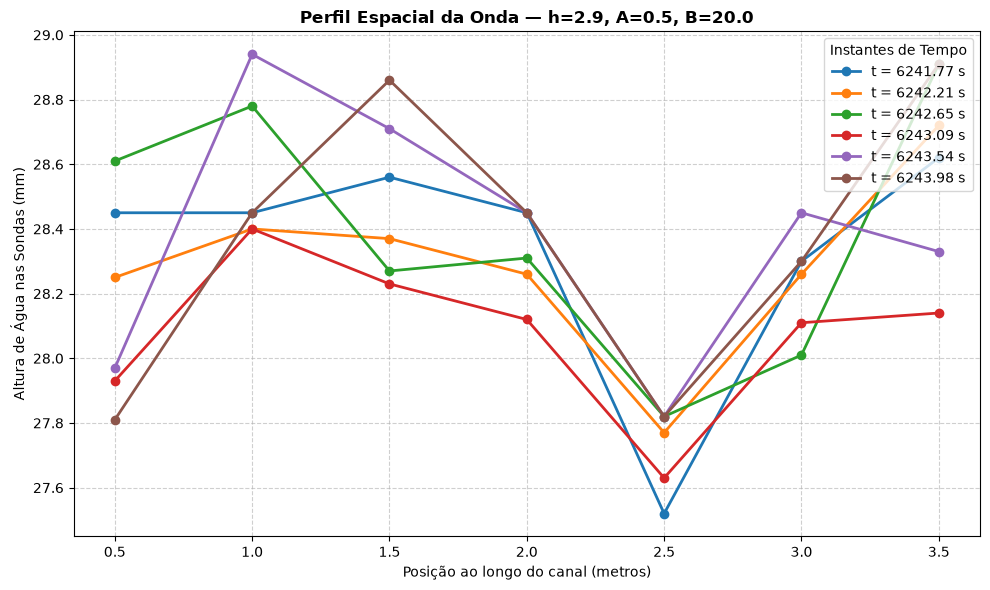